# Partial CE Loss for Point-Supervised Remote Sensing Segmentation

End-to-end notebook (Google Colab, GPU runtime). It:
1. installs dependencies and downloads a **LoveDA** subset,
2. sanity-checks the **partial losses** and **point sampling**,
3. runs **Experiment 1 (annotation density)** and **Experiment 2 (loss type)**,
4. trains a **fully-supervised upper bound** for context,
5. produces the tables / figures used in the technical report.

> Set Runtime -> Change runtime type -> GPU before running.

## 1. Setup

In [1]:
!pip -q install segmentation-models-pytorch "albumentations>=1.3.0" opencv-python-headless tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 13.5 MB/s eta 0:00:00


The next cell **auto-clones your GitHub repo** into Colab and puts the `src/`
package on the import path. Just run it -- no manual editing needed. (Re-running
is safe; it skips cloning if the folder already exists.)

In [2]:
# Auto-clone the repo and make the src/ package importable. Idempotent: safe to re-run.
import os, sys, glob

REPO_URL = 'https://github.com/HamzaImtiaz03/segmentation_project.git'
CLONE_DIR = '/content/segmentation_project'

if not os.path.isdir(CLONE_DIR):
    os.system(f'git clone {REPO_URL} {CLONE_DIR}')

# Locate the folder that actually contains src/__init__.py (robust to folder name).
project_root = None
candidates = [CLONE_DIR] + [os.path.dirname(os.path.dirname(p))
                            for p in glob.glob('/content/**/src/__init__.py', recursive=True)]
for root in candidates:
    if os.path.isfile(os.path.join(root, 'src', '__init__.py')):
        project_root = root
        break

assert project_root, 'src/ package not found -- did the clone succeed? Check the Files panel.'
os.chdir(project_root)
if project_root not in sys.path:
    sys.path.insert(0, project_root)
print('Project root:', project_root)
import src.losses  # fails loudly if the path is wrong
print('src package imported OK')

Project root: /content/segmentation_project
src package imported OK


## 2. Download LoveDA (Train + Val)
Hosted on Zenodo (record 5706578). This pulls ~1.5 GB; the experiments below only use a capped subset.

In [3]:
import os
os.makedirs('data/LoveDA', exist_ok=True)
if not os.path.isdir('data/LoveDA/Train'):
    !wget -q https://zenodo.org/record/5706578/files/Train.zip -O Train.zip
    !wget -q https://zenodo.org/record/5706578/files/Val.zip -O Val.zip
    !unzip -q Train.zip -d data/LoveDA
    !unzip -q Val.zip -d data/LoveDA
print(os.listdir('data/LoveDA'))

['Val', 'Train']


In [4]:
import torch
from src.config import Config, CLASS_NAMES, NUM_CLASSES

# Shared settings for every run (kept small so a full sweep finishes on a free Colab GPU).
BASE = dict(data_root='data/LoveDA', image_size=512,
            subset_train=300, subset_val=100,
            epochs=15, batch_size=8, num_workers=2)
print('Device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

Device: Tesla T4


## 3. Sanity checks
### 3a. Partial CE with a full mask must equal standard cross entropy

In [5]:
import torch, torch.nn as nn
from src.losses import PartialCrossEntropyLoss

logits = torch.randn(2, NUM_CLASSES, 16, 16)
target = torch.randint(0, NUM_CLASSES, (2, 16, 16))
pce = PartialCrossEntropyLoss()(logits, target).item()   # mask = all pixels
ce = nn.CrossEntropyLoss()(logits, target).item()
print(f'partial CE = {pce:.6f} | nn.CrossEntropy = {ce:.6f} | diff = {abs(pce-ce):.2e}')
assert abs(pce - ce) < 1e-5, 'partial CE should reduce to standard CE on a full mask'
print('OK')

partial CE = 2.330903 | nn.CrossEntropy = 2.330904 | diff = 4.77e-07
OK


### 3b. Point sampling: visualize full mask vs simulated points

train tiles: 300 | val tiles: 100
labeled pixels: 40 of 262144


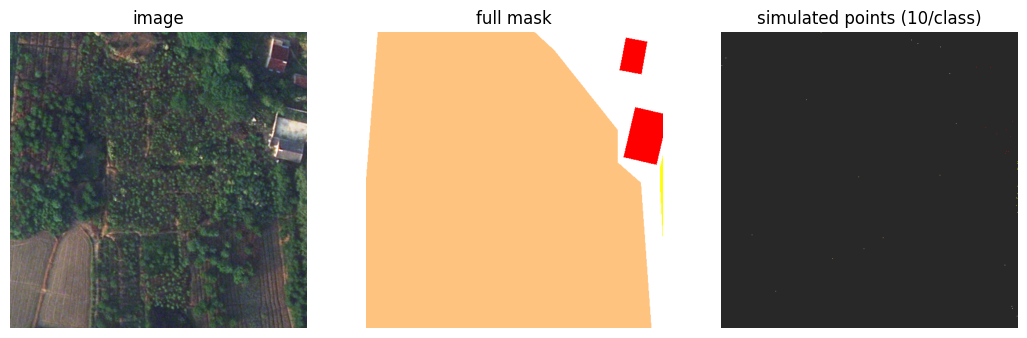

In [6]:
import numpy as np, matplotlib.pyplot as plt
from src.config import Config, IGNORE_INDEX
from src.dataset import build_datasets
from src.evaluate import colorize, denormalize

cfg = Config(**BASE, points_per_class=10)
train_ds, val_ds = build_datasets(cfg)
print('train tiles:', len(train_ds), '| val tiles:', len(val_ds))

s = train_ds[0]
full = s['full_mask'].numpy(); sparse = s['sparse_label'].numpy()
pts = np.full((*sparse.shape, 3), 40, np.uint8)
lab = sparse != IGNORE_INDEX
pts[lab] = colorize(np.where(lab, sparse, 0))[lab]
print('labeled pixels:', int(lab.sum()), 'of', lab.size)

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, im, t in zip(ax, [denormalize(s['image'], cfg), colorize(full), pts],
                    ['image', 'full mask', 'simulated points (10/class)']):
    a.imshow(im); a.set_title(t); a.axis('off')
plt.show()

## 4. Experiment 1 -- Annotation density
**Purpose:** how does the number of labeled points per class affect performance?

**Hypothesis:** mIoU rises with more points but with diminishing returns; thanks to transfer learning even very sparse supervision recovers a large share of full-mask performance.

Everything else (model, splits, epochs, seed, focal loss) is held fixed.

In [7]:
from src.train import train_model
from src.config import Config

densities = [1, 5, 10, 20, 50]
density_results = {}
for n in densities:
    print(f'\n===== points/class = {n} =====')
    cfg = Config(**BASE, supervision='points', points_per_class=n,
                 loss='focal', out_dir=f'runs/pts_{n}')
    density_results[n] = train_model(cfg)


===== points/class = 1 =====


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:122: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

/content/segmentation_project/src/train.py:83: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
epoch 1/15:   0%|          | 0/37 [00:00<?, ?it/s]/content/segmentation_project/src/train.py:103: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


...

epoch 11 | loss 0.1396 | mIoU 0.3232 | F1 0.4763 | OA 0.5462


epoch 12 | loss 0.1275 | mIoU 0.3031 | F1 0.4539 | OA 0.5170


epoch 13 | loss 0.1262 | mIoU 0.2892 | F1 0.4372 | OA 0.5086


epoch 14 | loss 0.1278 | mIoU 0.3093 | F1 0.4600 | OA 0.5318


epoch 15 | loss 0.1225 | mIoU 0.3108 | F1 0.4636 | OA 0.5224


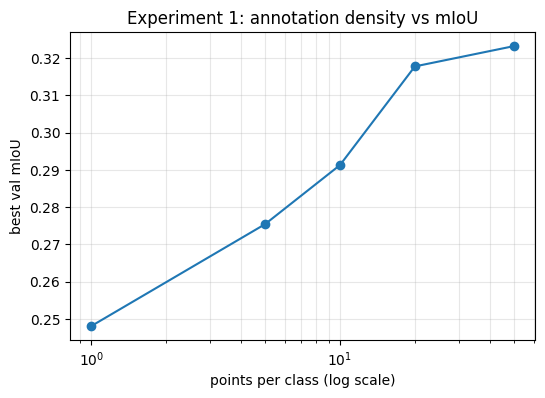

  1 points/class -> mIoU 0.2481
  5 points/class -> mIoU 0.2754
 10 points/class -> mIoU 0.2913
 20 points/class -> mIoU 0.3177
 50 points/class -> mIoU 0.3232


In [8]:
import matplotlib.pyplot as plt, os
os.makedirs('report', exist_ok=True)

xs = densities
ys = [density_results[n]['best_miou'] for n in densities]
plt.figure(figsize=(6, 4))
plt.plot(xs, ys, 'o-')
plt.xscale('log'); plt.xlabel('points per class (log scale)'); plt.ylabel('best val mIoU')
plt.title('Experiment 1: annotation density vs mIoU'); plt.grid(True, which='both', alpha=0.3)
plt.savefig('report/fig_density.png', dpi=120, bbox_inches='tight'); plt.show()
for n, y in zip(xs, ys):
    print(f'{n:>3} points/class -> mIoU {y:.4f}')

## 5. Experiment 2 -- Loss type (partial CE vs partial focal)
**Purpose:** does focal loss help over plain partial CE under sparse supervision?

**Hypothesis:** focal down-weights easy/abundant pixels, improving IoU on rarer classes. Points/class fixed at 10.

In [9]:
loss_results = {}
for loss_name in ['ce', 'focal']:
    print(f'\n===== loss = {loss_name} =====')
    cfg = Config(**BASE, supervision='points', points_per_class=10,
                 loss=loss_name, out_dir=f'runs/loss_{loss_name}')
    loss_results[loss_name] = train_model(cfg)


===== loss = ce =====


epoch 01 | loss 1.9259 | mIoU 0.1275 | F1 0.2164 | OA 0.2900


epoch 02 | loss 1.5491 | mIoU 0.2157 | F1 0.3332 | OA 0.4488


epoch 03 | loss 1.3959 | mIoU 0.2032 | F1 0.3150 | OA 0.3949


epoch 04 | loss 1.2634 | mIoU 0.2667 | F1 0.3975 | OA 0.5033


...

epoch 11 | loss 0.1508 | mIoU 0.3273 | F1 0.4839 | OA 0.5554


epoch 12 | loss 0.1437 | mIoU 0.3148 | F1 0.4694 | OA 0.5272


epoch 13 | loss 0.1399 | mIoU 0.3088 | F1 0.4656 | OA 0.5043


epoch 14 | loss 0.1382 | mIoU 0.3268 | F1 0.4839 | OA 0.5462


epoch 15 | loss 0.1385 | mIoU 0.3222 | F1 0.4799 | OA 0.5326


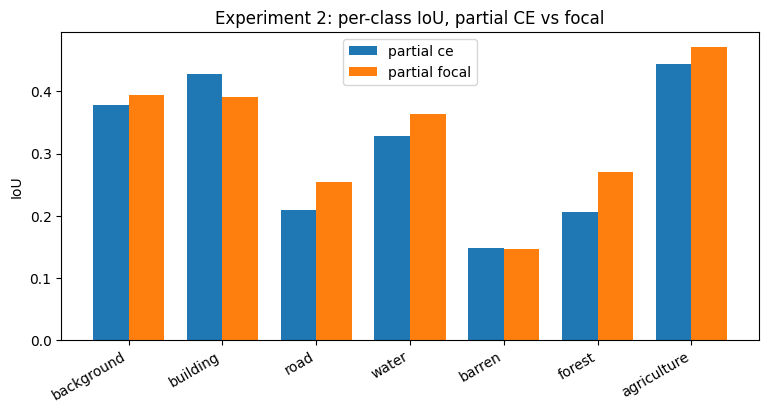

partial ce   : mIoU 0.3057
partial focal: mIoU 0.3273


In [10]:
import numpy as np, matplotlib.pyplot as plt
x = np.arange(NUM_CLASSES); w = 0.38
plt.figure(figsize=(9, 4))
for i, name in enumerate(['ce', 'focal']):
    iou = np.array(loss_results[name]['best_per_class_iou'], dtype=float)
    plt.bar(x + (i - 0.5) * w, np.nan_to_num(iou), width=w, label=f'partial {name}')
plt.xticks(x, CLASS_NAMES, rotation=30, ha='right'); plt.ylabel('IoU')
plt.title('Experiment 2: per-class IoU, partial CE vs focal'); plt.legend()
plt.savefig('report/fig_loss_perclass.png', dpi=120, bbox_inches='tight'); plt.show()
for name in ['ce', 'focal']:
    print(f"partial {name:5s}: mIoU {loss_results[name]['best_miou']:.4f}")

## 6. Fully-supervised upper bound (context)
Train once on the complete masks to express the point-supervised results as a percentage of full supervision.

In [11]:
cfg = Config(**BASE, supervision='full', loss='ce', out_dir='runs/full')
full_result = train_model(cfg)
print('full-supervision mIoU:', full_result['best_miou'])

/content/segmentation_project/src/train.py:83: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
epoch 1/15:   0%|          | 0/37 [00:00<?, ?it/s]/content/segmentation_project/src/train.py:103: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


epoch 01 | loss 1.5264 | mIoU 0.1800 | F1 0.2751 | OA 0.4287


epoch 02 | loss 1.1298 | mIoU 0.2426 | F1 0.3577 | OA 0.5332


epoch 03 | loss 1.0232 | mIoU 0.2391 | F1 0.3397 | OA 0.5839


epoch 04 | loss 0.9633 | mIoU 0.2850 | F1 0.4013 | OA 0.6061


...

epoch 11 | loss 0.7235 | mIoU 0.3086 | F1 0.4260 | OA 0.6481


epoch 12 | loss 0.7053 | mIoU 0.3265 | F1 0.4421 | OA 0.6593


epoch 13 | loss 0.6916 | mIoU 0.3253 | F1 0.4475 | OA 0.6502


epoch 14 | loss 0.6760 | mIoU 0.3322 | F1 0.4511 | OA 0.6600


epoch 15 | loss 0.6713 | mIoU 0.3387 | F1 0.4562 | OA 0.6637
full-supervision mIoU: 0.33871253101266147


## 7. Summary table + qualitative predictions

In [12]:
full_miou = full_result['best_miou']
print(f"{'setting':<28}{'mIoU':>8}{'% of full':>12}")
print('-' * 48)
for n in densities:
    m = density_results[n]['best_miou']
    print(f"{'focal, '+str(n)+' pts/class':<28}{m:>8.4f}{100*m/full_miou:>11.1f}%")
print(f"{'full supervision':<28}{full_miou:>8.4f}{100.0:>11.1f}%")

setting                         mIoU   % of full
------------------------------------------------
focal, 1 pts/class            0.2481       73.2%
focal, 5 pts/class            0.2754       81.3%
focal, 10 pts/class           0.2913       86.0%
focal, 20 pts/class           0.3177       93.8%
focal, 50 pts/class           0.3232       95.4%
full supervision              0.3387      100.0%


class              IoU
background      0.2872
building        0.3785
road            0.2102
water           0.3934
barren          0.1335
forest          0.1989
agriculture     0.4373
----------------------
mIoU            0.2913
macro-F1        0.4405
overall acc     0.4875
saved report/fig_qualitative.png


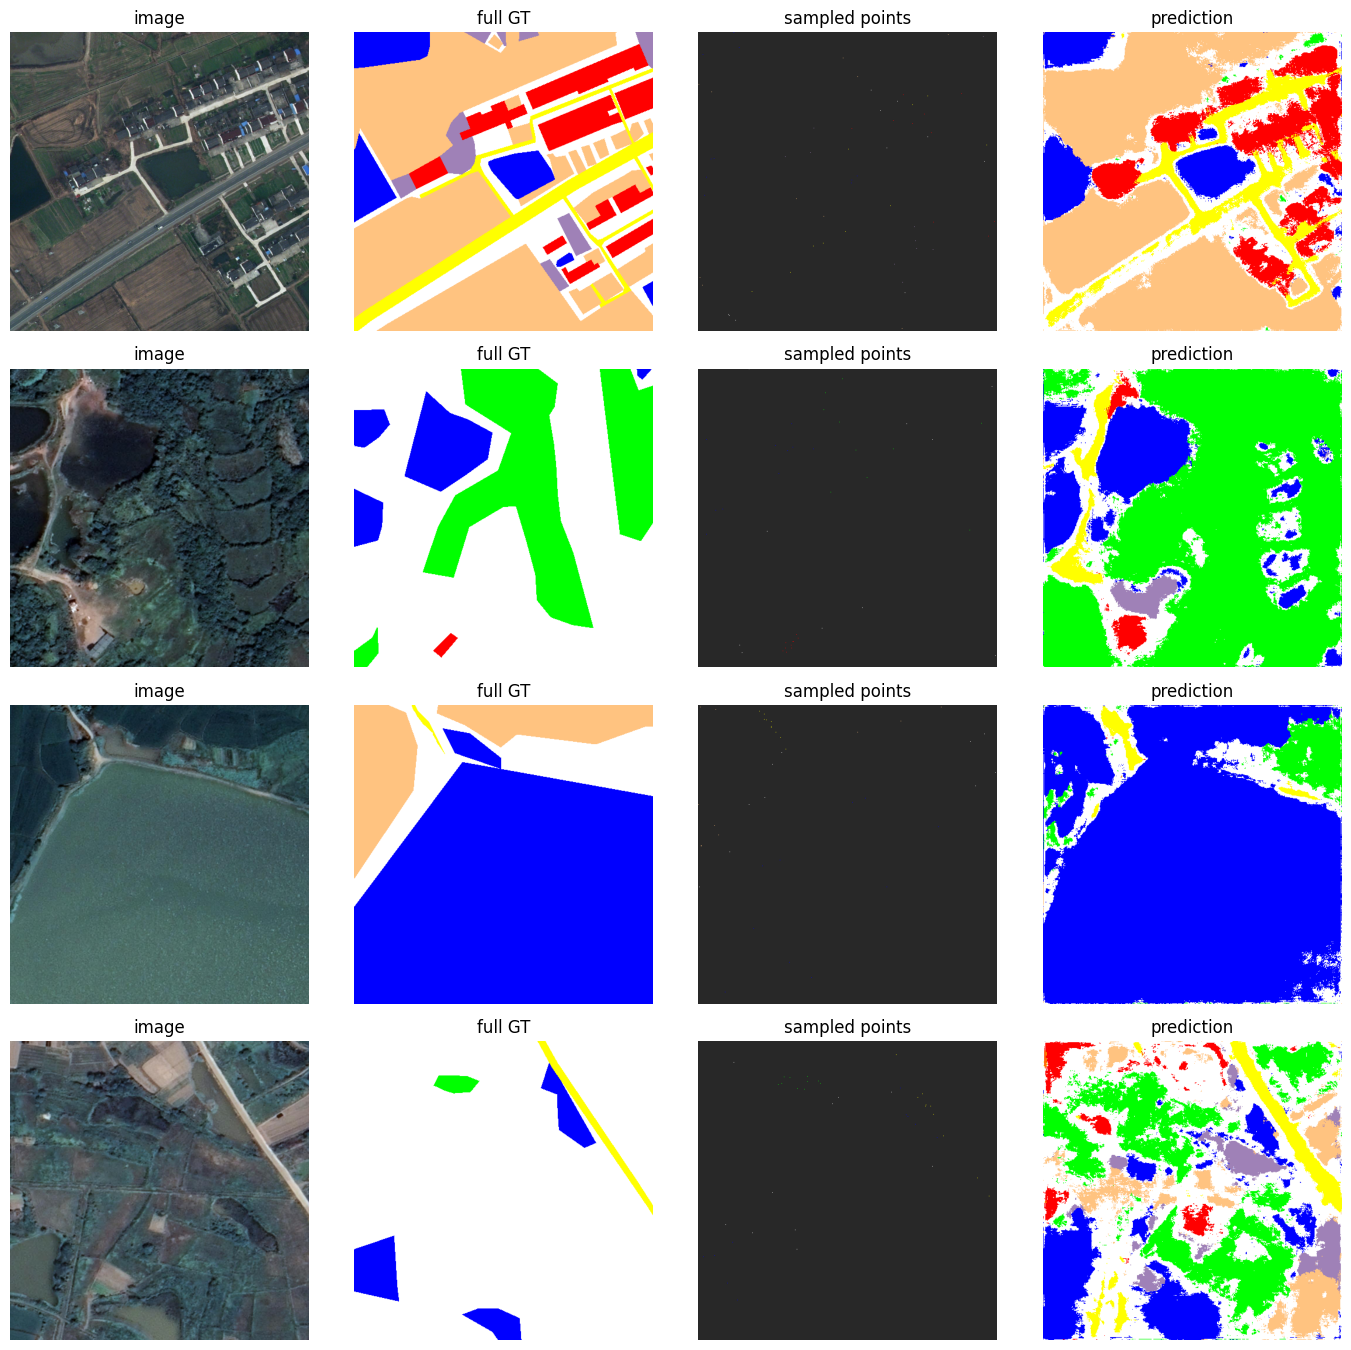

In [14]:
import torch
from src.config import Config
from src.model import build_model
from src.dataset import build_datasets
from src.evaluate import visualize_predictions, compute_metrics, metrics_table
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Load our own checkpoint with weights_only=False (trusted; it stores config+metrics).
ckpt = torch.load('runs/pts_10/best.pt', map_location=device, weights_only=False)
ckpt_cfg = Config(**ckpt['config'])
model = build_model(ckpt_cfg).to(device)
model.load_state_dict(ckpt['model'])

_, val_ds = build_datasets(ckpt_cfg)
print(metrics_table(compute_metrics(model, DataLoader(val_ds, batch_size=ckpt_cfg.batch_size), device)))

fig = visualize_predictions(model, val_ds, device, indices=[0, 1, 2, 3])
fig.savefig('report/fig_qualitative.png', dpi=120, bbox_inches='tight')
print('saved report/fig_qualitative.png')

In [13]:
import torch
from src.evaluate import load_checkpoint, visualize_predictions, compute_metrics, metrics_table
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model, ckpt_cfg = load_checkpoint('runs/pts_10/best.pt', device)
_, val_ds = build_datasets(ckpt_cfg)
print(metrics_table(compute_metrics(model, DataLoader(val_ds, batch_size=ckpt_cfg.batch_size), device)))

fig = visualize_predictions(model, val_ds, device, indices=[0, 1, 2, 3])
fig.savefig('report/fig_qualitative.png', dpi=120, bbox_inches='tight')

UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray._reconstruct was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray._reconstruct])` or the `torch.serialization.safe_globals([numpy._core.multiarray._reconstruct])` context manager to allowlist this global if you trust this class/function.

Check the documentation of to

## 8. Conclusions
Fill in once the runs finish (see `report/technical_report.md`):
* the point where extra points stop helping (diminishing returns),
* whether partial focal beats partial CE and on which classes,
* how close sparse point supervision gets to the full-mask upper bound.